           Region         Date  Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                             3.65   
1  Andhra Pradesh   30-06-2019    Monthly                             3.05   
2  Andhra Pradesh   31-07-2019    Monthly                             3.75   
3  Andhra Pradesh   31-08-2019    Monthly                             3.32   
4  Andhra Pradesh   30-09-2019    Monthly                             5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                                     43.97  Rural  
4           12256762.0                                     44.68  Rural  
Index(['Region', ' Date', ' Frequency', 'Estimated Unemployment Rate (%)',
       ' Est

C:\Users\kprav\AppData\Local\Temp\ipykernel_3144\3846811918.py:17: UserWarning: Parsing dates in  %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


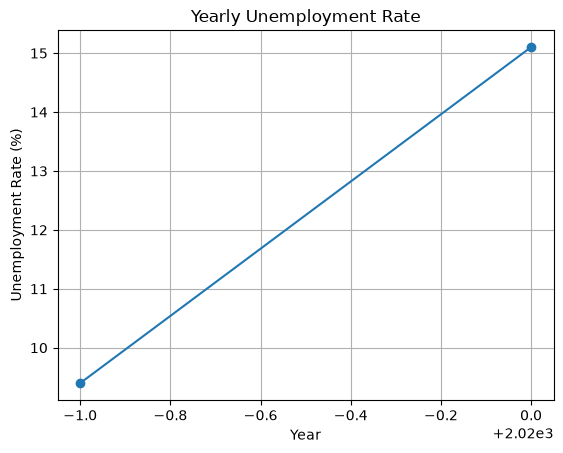

Before COVID: 9.399046511627906
During COVID: 15.10158064516129


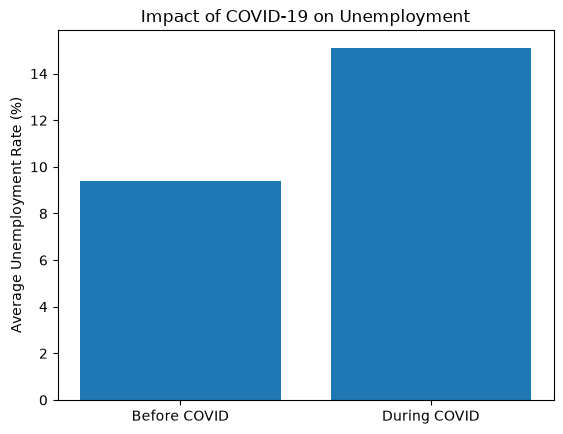

Month
1      9.950755
2      9.964717
3     10.700577
4     23.641569
5     16.646190
6     10.553462
7      9.033889
8      9.637925
9      9.051731
10     9.900909
11     9.868364
12     9.497358
Name: Unemployment_Rate, dtype: float64


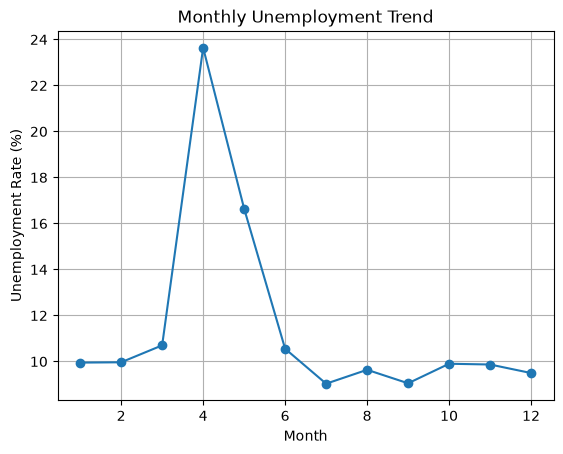

Region
Andhra Pradesh       7.477143
Assam                6.428077
Bihar               18.918214
Chandigarh          15.991667
Chhattisgarh         9.240357
Delhi               16.495357
Goa                  9.274167
Gujarat              6.663929
Haryana             26.283214
Himachal Pradesh    18.540357
Jammu & Kashmir     16.188571
Jharkhand           20.585000
Karnataka            6.676071
Kerala              10.123929
Madhya Pradesh       7.406429
Maharashtra          7.557500
Meghalaya            4.798889
Odisha               5.657857
Puducherry          10.215000
Punjab              12.031071
Rajasthan           14.058214
Sikkim               7.249412
Tamil Nadu           9.284286
Telangana            7.737857
Tripura             28.350357
Uttar Pradesh       12.551429
Uttarakhand          6.582963
West Bengal          8.124643
Name: Unemployment_Rate, dtype: float64
Tripura
Meghalaya


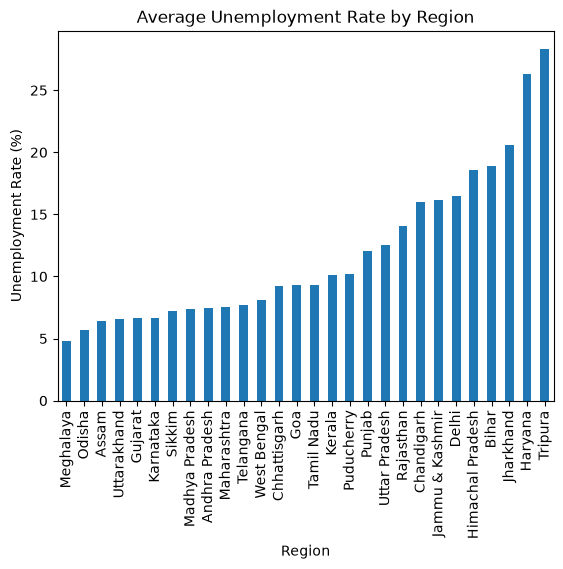

                                         Unemployment_Rate  \
Unemployment_Rate                                 1.000000   
Estimated Employed                               -0.222876   
Estimated Labour Participation Rate (%)           0.002558   
Year                                              0.262602   
Month                                            -0.122938   

                                         Estimated Employed  \
Unemployment_Rate                                 -0.222876   
Estimated Employed                                 1.000000   
Estimated Labour Participation Rate (%)            0.011300   
Year                                              -0.031841   
Month                                              0.011285   

                                         Estimated Labour Participation Rate (%)  \
Unemployment_Rate                                                       0.002558   
Estimated Employed                                                      0.011300

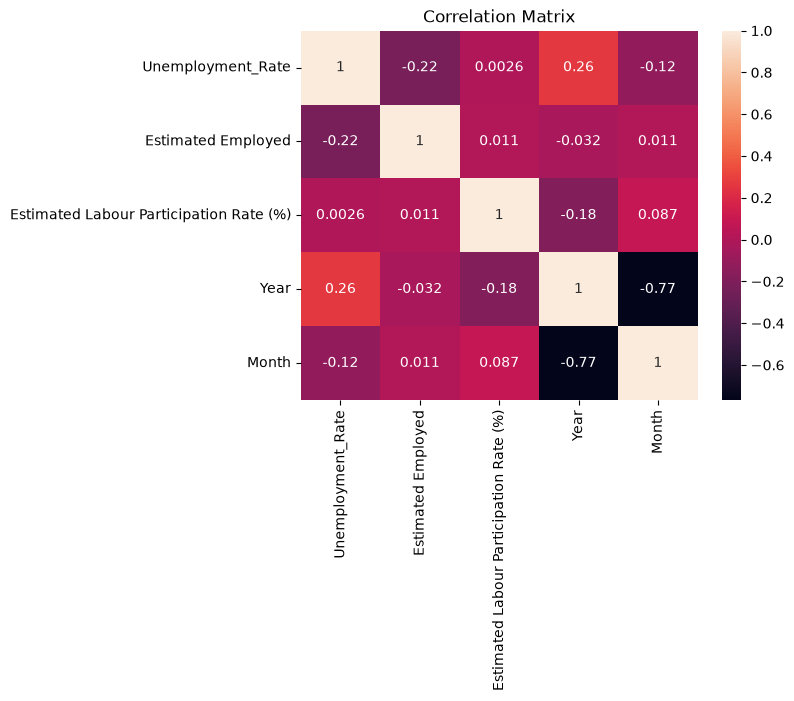

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Unemployment in India.csv")

print(df.head())
print(df.columns)
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
df = df.dropna()
print(df.isnull().sum())
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df = df.rename(columns={"Estimated Unemployment Rate (%)":"Unemployment_Rate"})
average = df["Unemployment_Rate"].mean()
print("Average unemployment rate:", average)
print(df.loc[df["Unemployment_Rate"].idxmax()])
print(df.loc[df["Unemployment_Rate"].idxmin()])
yearly = df.groupby("Year")["Unemployment_Rate"].mean()
print(yearly)
yearly.plot(kind="line", marker="o")
plt.title("Yearly Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.grid()
plt.show()
before = df[df["Year"] < 2020]
covid = df[df["Year"].isin([2020, 2021])]
print("Before COVID:",
      before["Unemployment_Rate"].mean())
print("During COVID:",
      covid["Unemployment_Rate"].mean())
periods = ["Before COVID", "During COVID"]

values = [
    before["Unemployment_Rate"].mean(),
    covid["Unemployment_Rate"].mean()
]

plt.bar(periods, values)

plt.title("Impact of COVID-19 on Unemployment")
plt.ylabel("Average Unemployment Rate (%)")

plt.show()
monthly = df.groupby("Month")["Unemployment_Rate"].mean()
print(monthly)
monthly.plot(kind="line", marker="o")
plt.title("Monthly Unemployment Trend")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.grid()
plt.show()
region = df.groupby("Region")["Unemployment_Rate"].mean()
print(region)
print(region.idxmax())
print(region.idxmin())
region.sort_values().plot(kind="bar")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Unemployment Rate (%)")
plt.show()
print(df.corr(numeric_only=True))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title("Correlation Matrix")
plt.show()
